In [1]:
%pip install pandas openpyxl matplotlib seaborn scikit-learn networkx numpy

Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path
import itertools, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Update this path if the workbook is moved.
FILE = Path(r"C:\Users\ritab\OneDrive\Practical sets\Dataset1 for cars.xlsx")
SHEET = 0
sns.set_theme(style="whitegrid")
df = pd.read_excel(FILE, sheet_name=SHEET)

# Normalize column names for robust access while retaining the original data.
def find_col(fragment):
    hits = [c for c in df.columns if fragment.lower() in str(c).lower()]
    if len(hits) != 1:
        raise ValueError(f"Expected one column containing {fragment!r}; found {hits}. Columns: {list(df.columns)}")
    return hits[0]
YEAR = find_col("year")
COST = find_col("cost")
SPEED = find_col("speed (in km/hr)")
SEATS = find_col("seats")
NAME = next((c for c in df.columns if "name" in str(c).lower()), None)
for c in [YEAR, COST, SPEED, SEATS]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Rows, columns:", df.shape)
display(df.head(10))
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
if df[[YEAR, COST, SPEED, SEATS]].isna().any().any():
    raise ValueError("Year, cost, speed, and seats must be numeric and non-missing for this analysis.")


Rows, columns: (10, 6)


,Name of car,year,mileage,number of seats,speed (in km/hr),cost
0,Car 1,2023,20000,2,300,70000
1,Car 2,2024,30000,3,400,80000
2,Car 3,2025,40000,4,500,90000
3,Car 4,2026,50000,5,600,100000
4,Car 5,2027,60000,6,700,110000
5,Car 6,2028,70000,7,800,120000
6,Car 7,2029,80000,8,900,130000
7,Car 8,2030,90000,9,1000,140000
8,Car 9,2031,100000,10,1100,150000
9,Car 10,2032,110000,11,1200,160000


Missing values:
 Name of car         0
year                0
mileage             0
number of seats     0
speed (in km/hr)    0
cost                0
dtype: int64
Duplicate rows: 0


                  count      mean           std      min       25%       50%  \
year               10.0    2027.5      3.027650   2023.0   2025.25    2027.5   
cost               10.0  115000.0  30276.503541  70000.0  92500.00  115000.0   
speed (in km/hr)   10.0     750.0    302.765035    300.0    525.00     750.0   
number of seats    10.0       6.5      3.027650      2.0      4.25       6.5   

                        75%       max  
year                2029.75    2032.0  
cost              137500.00  160000.0  
speed (in km/hr)     975.00    1200.0  
number of seats        8.75      11.0  
Trend model: cost = -20,160,000.000 + 10,000.000 × year
In-sample R² = 1.0000 (descriptive fit; not out-of-sample validation)


,year,predicted_cost
0,2033,"170,000.00"
1,2034,"180,000.00"
2,2035,"190,000.00"
3,2036,"200,000.00"
4,2037,"210,000.00"
5,2038,"220,000.00"
6,2039,"230,000.00"
7,2040,"240,000.00"
8,2041,"250,000.00"
9,2042,"260,000.00"


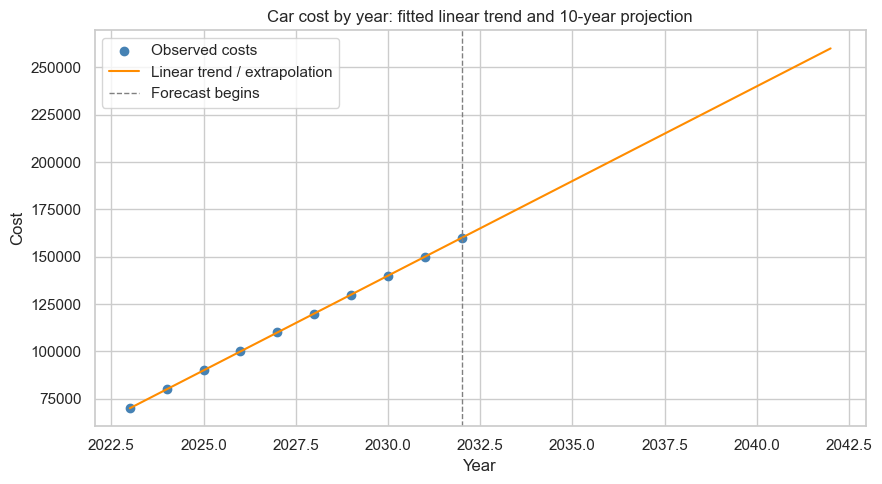

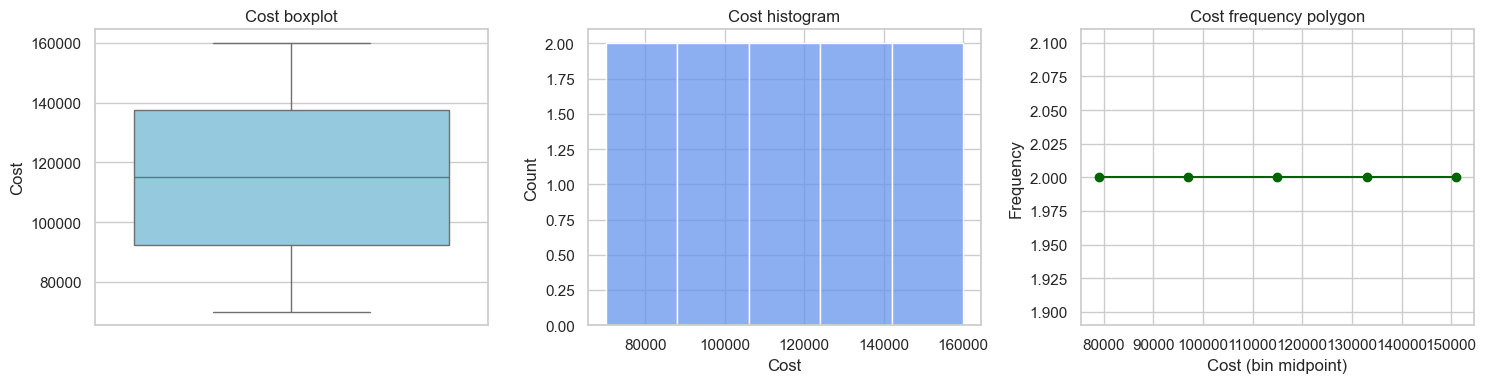

In [7]:
# Descriptive statistics and trend fit
print(df[[YEAR, COST, SPEED, SEATS]].describe().T)
X = df[[YEAR]].to_numpy()
y = df[COST].to_numpy()
model = LinearRegression().fit(X, y)
print(f"Trend model: cost = {model.intercept_:,.3f} + {model.coef_[0]:,.3f} × year")
print(f"In-sample R² = {model.score(X, y):.4f} (descriptive fit; not out-of-sample validation)")

last_year = int(df[YEAR].max())
future_years = np.arange(last_year + 1, last_year + 11)
pred = model.predict(future_years.reshape(-1, 1))
forecast_df = pd.DataFrame({"year": future_years, "predicted_cost": pred})
display(forecast_df.style.format({"predicted_cost": "{:,.2f}"}))

# Scatterplot with fitted line and projected decade
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df[YEAR], df[COST], color="steelblue", label="Observed costs")
fit_years = np.arange(int(df[YEAR].min()), int(future_years.max()) + 1)
ax.plot(fit_years, model.predict(fit_years.reshape(-1, 1)), color="darkorange", label="Linear trend / extrapolation")
ax.axvline(last_year, color="gray", linestyle="--", linewidth=1, label="Forecast begins")
ax.set(title="Car cost by year: fitted linear trend and 10-year projection", xlabel="Year", ylabel="Cost")
ax.legend(); plt.tight_layout(); plt.show()

# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df[COST], ax=axes[0], color="skyblue"); axes[0].set(title="Cost boxplot", ylabel="Cost")
sns.histplot(df[COST], bins="auto", kde=False, ax=axes[1], color="cornflowerblue"); axes[1].set(title="Cost histogram", xlabel="Cost")
# Frequency polygon: histogram bin midpoints joined by lines
counts, edges = np.histogram(df[COST], bins="auto")
mid = (edges[:-1] + edges[1:]) / 2
axes[2].plot(mid, counts, marker="o", color="darkgreen")
axes[2].set(title="Cost frequency polygon", xlabel="Cost (bin midpoint)", ylabel="Frequency")
plt.tight_layout(); plt.show()


Vertices: 10
Green speed-rule edges: 24
Yellow seats-rule edges: 45
Union graph edges: 45


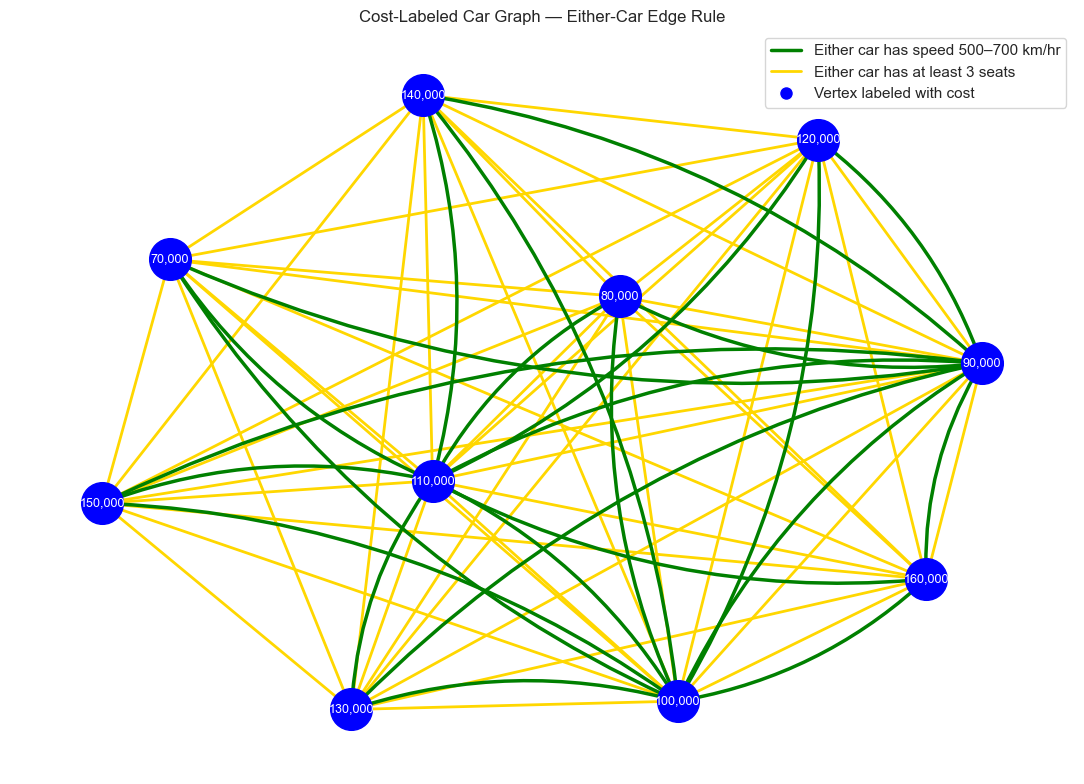

Chromatic number: 10
Chromatic index: 9
Independence number: 1
Clique number: 10
Crossing number: 60


In [9]:
import itertools
import math
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Each car record is a vertex labeled with its cost.
G = nx.Graph()

for i, (_, row) in enumerate(df.iterrows()):
    G.add_node(
        i,
        label=f"{row[COST]:,.0f}",
        cost=float(row[COST]),
        speed=float(row[SPEED]),
        seats=int(row[SEATS]),
    )

# A pair receives a relation if either endpoint's car meets that rule.
speed_ok = {
    v for v, data in G.nodes(data=True)
    if 500 <= data["speed"] <= 700
}
seats_ok = {
    v for v, data in G.nodes(data=True)
    if data["seats"] >= 3
}

speed_edges = set()
seats_edges = set()

for u, v in itertools.combinations(G.nodes, 2):
    if u in speed_ok or v in speed_ok:
        speed_edges.add((u, v))

    if u in seats_ok or v in seats_ok:
        seats_edges.add((u, v))

# The graph is the union of the two edge relations.
G.add_edges_from(speed_edges | seats_edges)

print(f"Vertices: {G.number_of_nodes()}")
print(f"Green speed-rule edges: {len(speed_edges)}")
print(f"Yellow seats-rule edges: {len(seats_edges)}")
print(f"Union graph edges: {G.number_of_edges()}")

# Draw every vertex blue and label it with cost.
pos = nx.spring_layout(G, seed=7)
fig, ax = plt.subplots(figsize=(11, 8))

nx.draw_networkx_nodes(
    G, pos, node_color="blue", node_size=900, ax=ax
)
nx.draw_networkx_labels(
    G,
    pos,
    labels=nx.get_node_attributes(G, "label"),
    font_color="white",
    font_size=9,
    ax=ax,
)

# Draw seat relations as straight yellow lines.
nx.draw_networkx_edges(
    G, pos,
    edgelist=sorted(seats_edges),
    edge_color="gold",
    width=2,
    ax=ax,
)

# Draw speed relations as curved green lines, so pairs meeting both
# rules show both colored relations.
nx.draw_networkx_edges(
    G, pos,
    edgelist=sorted(speed_edges),
    edge_color="green",
    width=2.5,
    connectionstyle="arc3,rad=0.15",
    arrows=True,
    arrowstyle="-",
    ax=ax,
)

legend = [
    Line2D([0], [0], color="green", lw=2.5,
           label="Either car has speed 500–700 km/hr"),
    Line2D([0], [0], color="gold", lw=2,
           label="Either car has at least 3 seats"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="blue", markersize=10,
           label="Vertex labeled with cost"),
]
ax.legend(handles=legend, loc="best")
ax.set_title("Cost-Labeled Car Graph — Either-Car Edge Rule")
ax.axis("off")
plt.tight_layout()
plt.show()

# For this dataset, the seats-rule relation connects every pair:
# one car has 2 seats, and all the others have at least 3.
# Thus the union graph is K_n, where n is the number of cars.
n = G.number_of_nodes()
if G.number_of_edges() == n * (n - 1) // 2:
    chromatic_number = n
    chromatic_index = n - 1 if n % 2 == 0 else n
    independence_number = 1
    clique_number = n
    crossing_number = (
        math.floor(n / 2)
        * math.floor((n - 1) / 2)
        * math.floor((n - 2) / 2)
        * math.floor((n - 3) / 2)
        // 4
    )
    print(f"Chromatic number: {chromatic_number}")
    print(f"Chromatic index: {chromatic_index}")
    print(f"Independence number: {independence_number}")
    print(f"Clique number: {clique_number}")
    print(f"Crossing number: {crossing_number}")
else:
    print(
        "The union graph is not complete. "
        "Exact crossing number is not calculated by this code."
    )